# CS 155 Miniproject 2: Image Features for Classification

Starter code. Question numbers (e.g. **1A**) refer to the instruction PDF. Answer all written questions in your report.

Each part starts with a **helpers** section that defines the provided functions. After that, the cells you need to write start with `# TODO`, and every other cell is provided and should run as is.

Use a GPU runtime (`Runtime → Change runtime type → T4 GPU`). Extracting the Part 2 features takes about 3–5 minutes on a GPU. They are cached, so re-running is fast.

In [2]:
import copy, io, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from transformers import CLIPModel, CLIPTokenizer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

CACHE_DIR = "/content/cache" if os.path.isdir("/content") else "./cache"   # extracted features are cached here
os.makedirs(CACHE_DIR, exist_ok=True)

Using device: cpu


# Part 1: PCA features

## Part 1 helpers

Run these cells. You do not need to edit or read them, and the functions they define are used below.

In [3]:
# ---- Data -------------------------------------------------------------------------------
CIFAR_URL = "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/0b2714987fa478483af9968de7c934580d0bb9a2/plain_text/"
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]


def _load_cifar(split):
    df = pd.read_parquet(CIFAR_URL + f"{split}-00000-of-00001.parquet")
    imgs = np.stack([np.array(Image.open(io.BytesIO(b["bytes"])).convert("RGB")) for b in df["img"]])
    return imgs, df["label"].to_numpy()


def load_cifar_splits(subset=None):
    """CIFAR-10 as uint8 images (N, 32, 32, 3) and integer labels, for the 50,000 training images
    and the 10,000 holdout images. `subset` keeps only the first `subset` training images.
    Returns X_train, y_train, X_hold, y_hold."""
    X_train, y_train = _load_cifar("train")
    X_hold, y_hold = _load_cifar("test")
    if subset is not None:
        X_train, y_train = X_train[:subset], y_train[:subset]
    return X_train, y_train, X_hold, y_hold


def show_examples(imgs, labels, n=20):
    fig, axes = plt.subplots(2, n // 2, figsize=(15, 3.4))
    for ax, i in zip(axes.flat, np.random.RandomState(1).choice(len(imgs), n, replace=False)):
        ax.imshow(imgs[i]); ax.set_title(CLASSES[labels[i]], fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()


def flatten_pixels(imgs):
    """(N, 32, 32, 3) uint8  ->  (N, 3072) float32 in [0, 1]"""
    return imgs.reshape(len(imgs), -1).astype(np.float32) / 255.0


RESULTS = {}   # method name -> holdout accuracy

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    RESULTS[name] = acc
    print(f"{name}: holdout accuracy = {acc:.4f}")
    return acc


def print_results():
    print(f"{'Method':<40}{'Holdout accuracy':>17}")
    print("-" * 57)
    for name, acc in RESULTS.items():
        print(f"{name:<40}{acc:>17.4f}")

In [4]:
# ---- PCA tools (these take your PCA functions as arguments) -------------------------------
def check_pca(fit_pca, transform_pca, reconstruct_pca, X, k=20):
    """Compare your PCA with sklearn's. Principal directions are only defined up to sign, so we
    compare the explained variance and the reconstructions instead of the coordinates."""
    mine, ref = fit_pca(X, k), PCA(k, svd_solver="full").fit(X)
    print("explained variance matches sklearn:",
          np.allclose(mine["explained_variance_ratio"][:k], ref.explained_variance_ratio_, atol=1e-4))
    print("reconstructions match sklearn:",
          np.allclose(reconstruct_pca(mine, transform_pca(mine, X)), ref.inverse_transform(ref.transform(X)), atol=1e-3))


def keep_top(pca, k):
    """The same fitted PCA, truncated to its top k components."""
    return {**pca, "components": pca["components"][:k]}


def plot_cumulative_variance(pca):
    cum_var = np.cumsum(pca["explained_variance_ratio"])
    for thr in (0.80, 0.90, 0.95, 0.99):
        print(f"{thr:.0%} of variance retained with k = {np.searchsorted(cum_var, thr) + 1}")
    k = np.arange(1, len(cum_var) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
    ax1.plot(k, pca["explained_variance_ratio"])
    ax1.set_xscale("log"); ax1.set_yscale("log")
    ax1.set_xlabel("component k"); ax1.set_ylabel("explained variance ratio of component k")
    ax1.set_title("per component (log-log)")
    ax2.plot(k, cum_var)
    ax2.set_xscale("log"); ax2.set_xlabel("number of components k"); ax2.set_ylabel("cumulative explained variance")
    ax2.set_title("cumulative")
    for ax in (ax1, ax2): ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def plot_reconstructions(pca, transform_pca, reconstruct_pca, imgs, ks=(10, 50, 100, 400), n=4):
    X = flatten_pixels(imgs[:n])
    fig, axes = plt.subplots(n, len(ks) + 1, figsize=(8, 7))
    for row in range(n):
        axes[row, 0].imshow(imgs[row]); axes[row, 0].set_title("original" if row == 0 else "")
        for col, k in enumerate(ks, start=1):
            p = keep_top(pca, k)
            rec = reconstruct_pca(p, transform_pca(p, X[row:row + 1]))[0]
            axes[row, col].imshow(np.clip(rec.reshape(32, 32, 3), 0, 1))
            if row == 0: axes[row, col].set_title(f"k = {k}")
    for ax in axes.flat: ax.axis("off")
    plt.tight_layout(); plt.show()


def pca_features(pca, transform_pca, ks, X_train, X_hold):
    """{k: (train features, holdout features)} for every k in ks."""
    return {k: (transform_pca(keep_top(pca, k), X_train), transform_pca(keep_top(pca, k), X_hold)) for k in ks}

In [5]:
# ---- Training -----------------------------------------------------------------------------
class Standardize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", torch.as_tensor(mean, dtype=torch.float32))
        self.register_buffer("std", torch.as_tensor(std, dtype=torch.float32))

    def forward(self, x):
        return (x - self.mean) / self.std


@torch.no_grad()
def loss_and_accuracy(net, X, y, batch_size=4096):
    """Mean cross-entropy and accuracy of `net` on tensors X, y (eval mode)."""
    net.eval()
    total, correct = 0.0, 0
    for i in range(0, len(X), batch_size):
        logits = net(X[i:i + batch_size])
        total += F.cross_entropy(logits, y[i:i + batch_size], reduction="sum").item()
        correct += (logits.argmax(1) == y[i:i + batch_size]).sum().item()
    return total / len(X), correct / len(X)


@torch.no_grad()
def predict(net, X, batch_size=4096):
    net.eval()
    X = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
    return torch.cat([net(X[i:i + batch_size]).argmax(1) for i in range(0, len(X), batch_size)]).cpu().numpy()


def train_torch(model, X_train, y_train, X_hold, y_hold, epochs=30, batch_size=256, lr=1e-3,
                verbose=False):
    """Train `model` on numpy features/labels with Adam and cross-entropy. Inputs are standardized
    with training-set statistics. After every epoch it records the training and holdout loss and
    accuracy in summary["history"]. Always trains for all `epochs` (no early stopping), then
    returns the network from the epoch with the best holdout accuracy, numbered from 1.
    Returns (net, summary). Use predict(net, X) to classify with the network."""
    mean, std = X_train.mean(0), X_train.std(0) + 1e-6
    net = nn.Sequential(Standardize(mean, std), model).to(DEVICE)
    Xtr = torch.as_tensor(X_train, dtype=torch.float32, device=DEVICE)
    ytr = torch.as_tensor(y_train, dtype=torch.long, device=DEVICE)
    Xho = torch.as_tensor(X_hold, dtype=torch.float32, device=DEVICE)
    yho = torch.as_tensor(y_hold, dtype=torch.long, device=DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=lr)

    history = {"train_loss": [], "holdout_loss": [], "train_acc": [], "holdout_acc": []}
    best_hold, best_state, best_epoch = -1.0, None, 0
    for epoch in range(epochs):
        net.train()
        order = torch.randperm(len(Xtr), device=DEVICE)
        for i in range(0, len(Xtr), batch_size):
            idx = order[i:i + batch_size]
            loss = F.cross_entropy(net(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        for split, (X, y) in {"train": (Xtr, ytr), "holdout": (Xho, yho)}.items():
            l, a = loss_and_accuracy(net, X, y)
            history[f"{split}_loss"].append(l); history[f"{split}_acc"].append(a)
        if verbose:
            print(f"  epoch {epoch:3d}  loss train {history['train_loss'][-1]:.4f} holdout {history['holdout_loss'][-1]:.4f}  "
                  f"acc train {history['train_acc'][-1]:.4f} holdout {history['holdout_acc'][-1]:.4f}")
        if history["holdout_acc"][-1] > best_hold:
            best_hold, best_state, best_epoch = history["holdout_acc"][-1], copy.deepcopy(net.state_dict()), epoch

    net.load_state_dict(best_state)
    summary = {"train_acc": history["train_acc"][best_epoch], "holdout_acc": best_hold, "epoch": best_epoch + 1,
               "n_params": sum(p.numel() for p in model.parameters()), "history": history}
    return net, summary


def run_grid(feature_sets, architectures, y_train, y_hold):
    """feature_sets is a dict {label: (X_train, X_hold)}, and architectures is a list of nn.Module
    classes, each constructed as Class(d_in). Results are keyed by the class name.
    Trains every architecture on every feature set. Returns {(label, name): (net, summary)}."""
    results = {}
    for label, (Xtr, Xho) in feature_sets.items():
        for cls in architectures:
            name = cls.__name__
            torch.manual_seed(SEED)
            t0 = time.time()
            net, s = train_torch(cls(Xtr.shape[1]), Xtr, y_train, Xho, y_hold)
            results[(label, name)] = (net, s)
            print(f"{str(label):>6} | {name:<22} params {s['n_params']:>9,}   train {s['train_acc']:.4f}   "
                  f"holdout {s['holdout_acc']:.4f}   best epoch {s['epoch']:>3}   ({time.time() - t0:.0f}s)")
    return results


def results_table(results):
    """One row per (features, network) pair, with the parameter count, best epoch, and accuracies at that epoch."""
    rows = [{"features": label, "network": name, "params": s["n_params"], "best epoch": s["epoch"],
             "train acc": round(s["train_acc"], 4), "holdout acc": round(s["holdout_acc"], 4)}
            for (label, name), (_, s) in results.items()]
    return pd.DataFrame(rows)


def plot_grid(results, ks, architectures, title):
    plt.figure(figsize=(7, 4))
    for j, name in enumerate(cls.__name__ for cls in architectures):
        plt.plot(ks, [results[(k, name)][1]["holdout_acc"] for k in ks], "o-", c=f"C{j}", label=f"{name} (holdout)")
        plt.plot(ks, [results[(k, name)][1]["train_acc"] for k in ks], "x--", c=f"C{j}", alpha=0.5)
    plt.xscale("log"); plt.xlabel("number of components k"); plt.ylabel("accuracy")
    plt.title(f"{title} (solid: holdout, dashed: train)")
    plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


def plot_curves(results, keys, title):
    """Loss and accuracy per epoch for each (feature set, network) in `keys`.
    Solid lines show the training set and dashed lines the holdout set."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
    for j, key in enumerate(keys):
        h = results[key][1]["history"]
        ep = np.arange(1, len(h["train_loss"]) + 1)
        name = f"{key[0]} / {key[1]}"
        ax1.plot(ep, h["train_loss"], "-", c=f"C{j}", label=name)
        ax1.plot(ep, h["holdout_loss"], "--", c=f"C{j}")
        ax2.plot(ep, h["train_acc"], "-", c=f"C{j}", label=name)
        ax2.plot(ep, h["holdout_acc"], "--", c=f"C{j}")
    ax1.set_ylabel("cross-entropy loss"); ax2.set_ylabel("accuracy")
    for ax in (ax1, ax2):
        ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    fig.suptitle(f"{title} (solid: train, dashed: holdout)")
    plt.tight_layout(); plt.show()

## Data

We train on the 50,000 CIFAR-10 training images and evaluate on a holdout set of 10,000 different images (CIFAR-10's test set). All accuracies you report, and all choices you make (number of components, architecture, prompts), use the holdout set.

`SUBSET` lets you use fewer training images while debugging. Set it back to `None` for your final results.

train: (50000, 3072)   holdout: (10000, 3072)


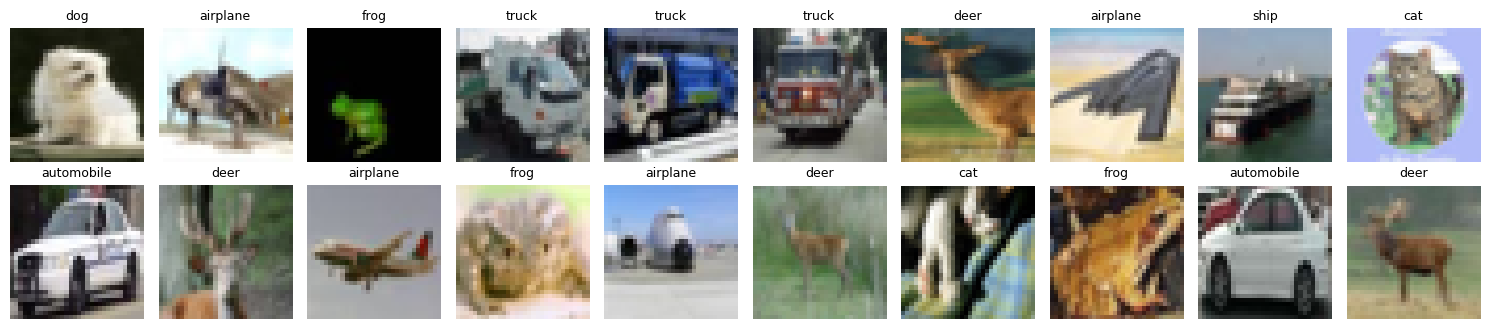

In [6]:
SUBSET = None   # e.g. 10_000 while debugging; None = all 50,000 training images

X_train_img, y_train, X_hold_img, y_hold = load_cifar_splits(SUBSET)
Xp_train, Xp_hold = flatten_pixels(X_train_img), flatten_pixels(X_hold_img)
print(f"train: {Xp_train.shape}   holdout: {Xp_hold.shape}")
show_examples(X_train_img, y_train)

## 1A. PCA

Implement PCA with `np.linalg.svd`, following the eigenfaces recipe from Lecture 9. Do not call `sklearn.decomposition.PCA` inside these functions. It is used only in the check below.

Note that the lecture slides store one image per **column** ($X$ is $D \times N$). Here each image is a **row** ($X$ is $N \times D$), so think about which factor of the SVD holds the principal directions.

In [7]:
# TODO 1A
def fit_pca(X_train, n_components):
    mean = X_train.mean(axis=0)
    Xc = X_train - mean
    # Rows are images (N x D): Xc = U S Vt, so the principal directions are the rows of Vt
    _, S, Vt = np.linalg.svd(Xc, full_matrices=False)   # S has min(N, D) entries, sorted descending
    var = S ** 2                                         # proportional to the variance along each direction
    return {
        "mean": mean,
        "components": Vt[:n_components],
        "explained_variance_ratio": var / var.sum(),
    }


def transform_pca(pca, X):
    return (X - pca["mean"]) @ pca["components"].T


def reconstruct_pca(pca, Z):
    return Z @ pca["components"] + pca["mean"]

In [8]:
check_pca(fit_pca, transform_pca, reconstruct_pca, Xp_train[:2000])

explained variance matches sklearn: True
reconstructions match sklearn: True


## 1B. Explained variance and reconstructions

One full SVD gives the variance spectrum for every $k$ at once (this takes a minute). The left plot shows the fraction of variance explained by each individual component on log-log axes. The right plot shows the cumulative fraction kept by the top $k$ components.

80% of variance retained with k = 33
90% of variance retained with k = 99
95% of variance retained with k = 217
99% of variance retained with k = 658


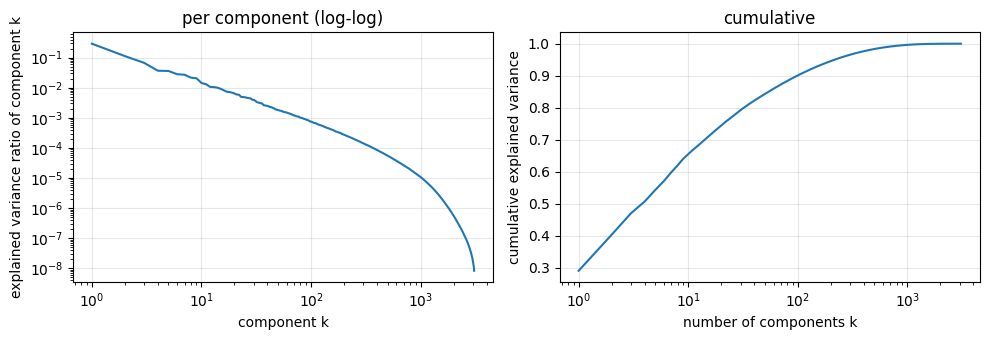

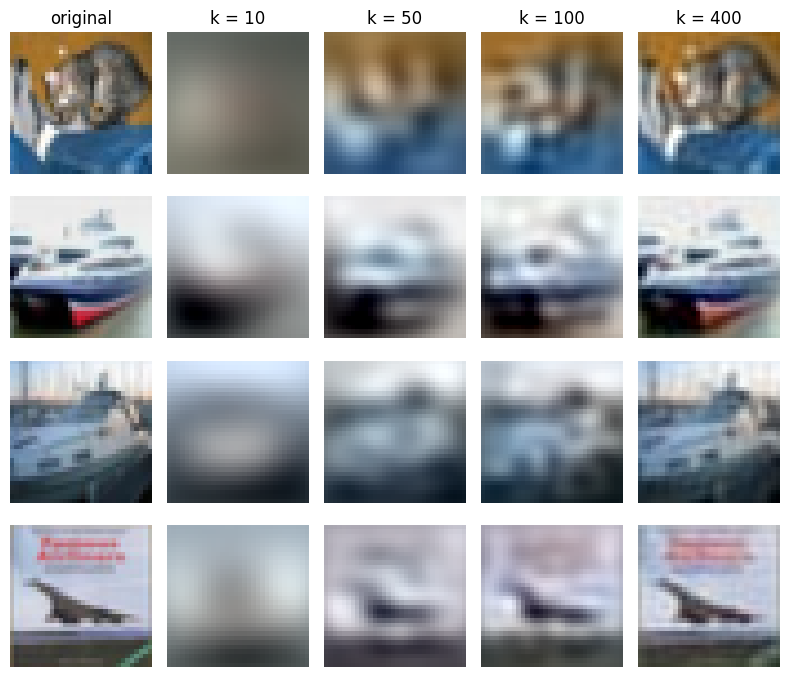

In [9]:
pca_full = fit_pca(Xp_train, Xp_train.shape[1])   # fit on the training set only
plot_cumulative_variance(pca_full)
plot_reconstructions(pca_full, transform_pca, reconstruct_pca, X_hold_img)

In [10]:
# TODO 1B
# K_LIST is a list of at least 4 ints between 1 and 3072, in increasing order.
# In 1D every network is trained on the PCA features for each k in K_LIST.
K_LIST = [10, 30, 100, 300, 1000]

## 1C. Networks

Each network is an `nn.Module` whose constructor takes the input dimension `d_in` and whose `forward` maps `(batch, d_in)` features to `(batch, 10)` logits. A single linear layer trained with cross-entropy is multinomial logistic regression, and `LogReg` below is provided as an example. Write at least two networks of increasing size (for example, a small MLP and a larger one), and list every network you want to train in `ARCHITECTURES`. Training is provided by `train_torch`, which runs Adam on standardized inputs for a fixed 30 epochs and keeps the epoch with the best holdout accuracy.

In [11]:
class LogReg(nn.Module):
    """Logistic regression, i.e. a single linear layer from d_in features to 10 logits."""
    def __init__(self, d_in):
        super().__init__()
        self.linear = nn.Linear(d_in, 10)

    def forward(self, x):
        return self.linear(x)

In [12]:
# TODO 1C
# Write at least two networks of increasing size (for example MLPs), then list every network in ARCHITECTURES.
# Each network is constructed as Class(d_in), where d_in is the input dimension (an int).
# forward takes a float tensor x of shape (batch, d_in) and returns a float tensor of shape (batch, 10)
# with one logit per class. Do not apply a softmax, since train_torch applies cross-entropy to the logits.
# TODO 1C
class SmallMLP(nn.Module):
    """One hidden layer of 256 units."""
    def __init__(self, d_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.net(x)


class LargeMLP(nn.Module):
    """Three hidden layers (1024-1024-512) with BatchNorm and dropout."""
    def __init__(self, d_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, 1024), nn.BatchNorm1d(1024), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(1024, 1024), nn.BatchNorm1d(1024), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(1024, 512),  nn.BatchNorm1d(512),  nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.net(x)


# A list of nn.Module classes (not instances)
ARCHITECTURES = [LogReg, SmallMLP, LargeMLP]

## 1D. Training every network on every $k$

In [ ]:
pixel_results = run_grid(pca_features(pca_full, transform_pca, K_LIST, Xp_train, Xp_hold), ARCHITECTURES, y_train, y_hold)
plot_grid(pixel_results, K_LIST, ARCHITECTURES, "PCA features")
best_k, best_arch = max(pixel_results, key=lambda key: pixel_results[key][1]["holdout_acc"])
RESULTS[f"PCA (k={best_k}) + {best_arch}"] = pixel_results[(best_k, best_arch)][1]["holdout_acc"]
results_table(pixel_results)

    10 | LogReg                 params       110   train 0.3177   holdout 0.3215   best epoch   6   (6s)
    10 | SmallMLP               params     5,386   train 0.3890   holdout 0.3913   best epoch  17   (13s)


In [ ]:
# Accuracy vs k with the best (k, architecture) marked
plt.figure(figsize=(7, 4))
for j, cls in enumerate(ARCHITECTURES):
    name = cls.__name__
    plt.plot(K_LIST, [pixel_results[(k, name)][1]["holdout_acc"] for k in K_LIST], "o-", c=f"C{j}", label=f"{name} (holdout)")
    plt.plot(K_LIST, [pixel_results[(k, name)][1]["train_acc"] for k in K_LIST], "x--", c=f"C{j}", alpha=0.5)
best_acc = pixel_results[(best_k, best_arch)][1]["holdout_acc"]
plt.scatter([best_k], [best_acc], s=250, facecolors="none", edgecolors="k", linewidths=2, zorder=5,
            label=f"best: k={best_k}, {best_arch} ({best_acc:.4f})")
plt.xscale("log"); plt.xlabel("number of components k"); plt.ylabel("accuracy")
plt.title("PCA features (solid: holdout, dashed: train)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"Best combination: k = {best_k}, {best_arch}, holdout accuracy = {best_acc:.4f}")

# Part 2: CLIP features

## Part 2 helpers

Run these cells. You do not need to edit or read them, and the functions they define are used below.

We use CLIP ViT-B/32 as a frozen feature extractor. All embeddings are L2-normalized, so a dot product is a cosine similarity.

In [ ]:
CLIP_NAME = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE).eval()
clip_tokenizer = CLIPTokenizer.from_pretrained(CLIP_NAME)

# CLIP's preprocessing resizes to 224x224 and normalizes with CLIP's statistics
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD  = (0.26862954, 0.26130258, 0.27577711)
clip_transform = T.Compose([
    T.ToPILImage(),
    T.Resize(224, interpolation=T.InterpolationMode.BICUBIC),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(CLIP_MEAN, CLIP_STD),
])


def _as_tensor(out):
    # Newer versions of transformers may return a ModelOutput instead of a tensor
    return out if torch.is_tensor(out) else out.pooler_output


class _ImageArray(torch.utils.data.Dataset):
    def __init__(self, imgs): self.imgs = imgs
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i): return clip_transform(self.imgs[i])


@torch.no_grad()
def get_clip_image_embeddings(imgs, batch_size=256, normalize=True):
    """imgs is a uint8 array (N, H, W, 3). Returns a float32 numpy array (N, 512)."""
    loader = torch.utils.data.DataLoader(_ImageArray(imgs), batch_size=batch_size,
                                         num_workers=2, shuffle=False)
    feats = []
    for batch in loader:
        f = _as_tensor(clip_model.get_image_features(pixel_values=batch.to(DEVICE)))
        if normalize:
            f = f / f.norm(dim=-1, keepdim=True)
        feats.append(f.float().cpu())
    return torch.cat(feats).numpy()


def cached_image_embeddings(name, imgs):
    path = f"{CACHE_DIR}/clip_{name}_{len(imgs)}.npy"
    if os.path.exists(path):
        return np.load(path)
    t0 = time.time()
    emb = get_clip_image_embeddings(imgs)
    np.save(path, emb)
    print(f"  {name}: {emb.shape} in {time.time() - t0:.0f}s")
    return emb


@torch.no_grad()
def get_clip_text_embeddings(texts, batch_size=256, normalize=True):
    """texts is a list of strings. Returns a float32 numpy array (len(texts), 512)."""
    feats = []
    for i in range(0, len(texts), batch_size):
        tok = clip_tokenizer(texts[i:i + batch_size], padding=True, return_tensors="pt").to(DEVICE)
        f = _as_tensor(clip_model.get_text_features(**tok))
        if normalize:
            f = f / f.norm(dim=-1, keepdim=True)
        feats.append(f.float().cpu())
    return torch.cat(feats).numpy()

## 2A. The same networks on CLIP features

We train every network from Part 1 on the 512-dimensional CLIP embeddings. The table lists each network's best epoch and its accuracies at that epoch, and the plot shows training and holdout loss and accuracy over the epochs for every network.

In [ ]:
Xc_train = cached_image_embeddings("train", X_train_img)
Xc_hold  = cached_image_embeddings("holdout", X_hold_img)
print(Xc_train.shape, Xc_hold.shape)

clip_results = run_grid({"CLIP": (Xc_train, Xc_hold)}, ARCHITECTURES, y_train, y_hold)
for name in (cls.__name__ for cls in ARCHITECTURES):
    evaluate(f"CLIP + {name}", y_hold, predict(clip_results[("CLIP", name)][0], Xc_hold))
results_table(clip_results)

In [ ]:
plot_curves(clip_results, [("CLIP", cls.__name__) for cls in ARCHITECTURES], "All networks on CLIP features")

# Part 3: Zero-shot classification

## Part 3 helpers

Run these cells. You do not need to edit or read them, and the functions they define are used below.

In [ ]:
def fill(template, classname):
    """Fill a template such as "a photo of a {}." (fixes "a airplane" -> "an airplane")."""
    return template.format(classname).replace(" a a", " an a")


def class_text_embeddings(template):
    """CLIP text embeddings, shape (10, 512), of the template filled with each class name, in CLASSES order."""
    return get_clip_text_embeddings([fill(template, c) for c in CLASSES])


def compare_templates(templates, zero_shot_classify):
    """Holdout accuracy of zero-shot classification (with your zero_shot_classify) for each template.
    Returns {template: accuracy}."""
    accs = {}
    for t in templates:
        accs[t] = accuracy_score(y_hold, zero_shot_classify(Xc_hold, class_text_embeddings(t)))
        print(f"{accs[t]:.4f}   {t!r}")
    return accs


def few_shot_indices(y, n_per_class, seed):
    """Indices of n_per_class random examples of each class."""
    rng = np.random.RandomState(seed)
    return np.concatenate([rng.choice(np.flatnonzero(y == c), n_per_class, replace=False)
                           for c in range(len(CLASSES))])


def fit_logreg(X, y):
    """Logistic regression fit to convergence on standardized features."""
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X, y)


def plot_label_sweep(sweep, shots, zero_shot_acc):
    """sweep is a dict {n: list of holdout accuracies}."""
    m = [np.mean(sweep[n]) for n in shots]; s = [np.std(sweep[n]) for n in shots]
    plt.figure(figsize=(7, 4))
    plt.errorbar(shots, m, yerr=s, marker="o", capsize=3, label="logistic regression on CLIP features")
    plt.axhline(zero_shot_acc, c="C3", ls="--", label="CLIP zero-shot")
    plt.xscale("log", base=2); plt.xticks(shots, shots)
    plt.xlabel("labeled training images per class"); plt.ylabel("holdout accuracy")
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 3A. Zero-shot classifier

Given image embeddings and one text embedding per class (all unit norm), predict for each image the class whose text embedding has the highest cosine similarity with it.

In [ ]:
# TODO 3A
def zero_shot_classify(image_embs, class_text_embs):
    """Predict a class for every image.

    Inputs
        image_embs       float array (N, 512), one L2-normalized CLIP image embedding per row
        class_text_embs  float array (n_classes, 512), one L2-normalized CLIP text embedding per class,
                         in class order
    Returns an int array (N,) with, for each image, the index of the class whose text embedding has
    the highest cosine similarity with it.
    """
    sims = image_embs @ class_text_embs.T     # (N, n_classes); unit norm, so these are cosine similarities
    return sims.argmax(axis=1)

In [ ]:
compare_templates(["a photo of a {}."], zero_shot_classify);

## 3B. Prompt templates

A template is a string with `{}` where the class name goes.

In [ ]:
# TODO 3B
# TEMPLATES is a list of strings, each with exactly one "{}" where the class name goes.
# Add at least three templates of your own below the four given ones.
TEMPLATES = [
    "{}",
    "a photo of a {}.",
    "a blurry photo of a {}.",
    "a drawing of a {}.",
    "a low resolution photo of a {}.",
    "a pixelated photo of a {}.",
    "a close-up photo of a {}.",
    "a photo of a small {}.",
    "a low-quality photo of a {}.",
]

In [ ]:
template_accs = compare_templates(TEMPLATES, zero_shot_classify)

BEST_TEMPLATE = max(template_accs, key=template_accs.get)
zs_acc = template_accs[BEST_TEMPLATE]
RESULTS[f"CLIP zero-shot ({BEST_TEMPLATE!r})"] = zs_acc
print(f"\nbest template: {BEST_TEMPLATE!r}   holdout accuracy = {zs_acc:.4f}")

In [ ]:
# All templates ranked by holdout accuracy
tbl = pd.Series(template_accs, name="holdout acc").sort_values(ascending=False).to_frame()
print(f"best:  {tbl.index[0]!r}  {tbl.iloc[0, 0]:.4f}")
print(f"worst: {tbl.index[-1]!r}  {tbl.iloc[-1, 0]:.4f}")
tbl

## 3C. How many labels is zero-shot worth?

We train logistic regression on only $n$ labeled CLIP embeddings per class and measure holdout accuracy. We repeat each $n$ with `N_DRAWS` random draws, because results vary a lot for small $n$. With so few labels there is nothing to tune, so we use `fit_logreg` instead of `train_torch`.

In [ ]:
SHOTS = [1, 2, 4, 8, 16, 32, 64, 128, 256]
N_DRAWS = 5

sweep = {}   # n -> list of N_DRAWS holdout accuracies
for n in SHOTS:
    for seed in range(N_DRAWS):
        idx = few_shot_indices(y_train, n, seed)        # n training indices per class
        clf = fit_logreg(Xc_train[idx], y_train[idx])
        sweep.setdefault(n, []).append(clf.score(Xc_hold, y_hold))
    print(f"n = {n:>3}   holdout accuracy {np.mean(sweep[n]):.4f} +- {np.std(sweep[n]):.4f}")

In [ ]:
plot_label_sweep(sweep, SHOTS, zs_acc)
print_results()

In [ ]:
# Smallest n at which few-shot logistic regression matches zero-shot (interpolated linearly in log2 n)
m = np.array([np.mean(sweep[n]) for n in SHOTS])
above = np.flatnonzero(m >= zs_acc)
if len(above) == 0:
    print(f"Zero-shot ({zs_acc:.4f}) beats logistic regression for every n up to {SHOTS[-1]}")
elif above[0] == 0:
    print(f"Logistic regression already matches zero-shot at n = {SHOTS[0]}")
else:
    j = above[0]
    lo, hi = np.log2(SHOTS[j - 1]), np.log2(SHOTS[j])
    n_eq = 2 ** (lo + (zs_acc - m[j - 1]) / (m[j] - m[j - 1]) * (hi - lo))
    print(f"Zero-shot ({zs_acc:.4f}) is worth about {n_eq:.0f} labeled images per class "
          f"(between n = {SHOTS[j-1]} and n = {SHOTS[j]})")

# Part 4: Attribute binding

## Part 4 helpers

Run these cells. You do not need to edit or read them, and the functions they define are used below.

In [ ]:
COLORS = {                      # name -> RGB
    "red":    (220,  30,  30),
    "green":  ( 30, 160,  60),
    "blue":   ( 30,  70, 220),
    "yellow": (240, 200,   0),
    "purple": (140,  50, 180),
}
SHAPES = ["circle", "square", "triangle", "star"]
IMG_SIZE = 224
TEMPLATE = "a photo of {}."     # {} is filled with e.g. "a green triangle and a yellow square"


def sample_scene(rng):
    """Two objects with different colors and shapes, one in each half of the canvas.
    'order' is the (random) order in which the caption mentions them."""
    colors = rng.choice(list(COLORS), size=2, replace=False)
    shapes = rng.choice(SHAPES, size=2, replace=False)
    sides = rng.permutation(2)                      # which object goes left (0) / right (1)
    objects = []
    for i in range(2):
        r = rng.uniform(28, 42)                     # object "radius" in pixels
        half = IMG_SIZE / 2
        cx = sides[i] * half + half / 2 + rng.uniform(-1, 1) * (half / 2 - r - 6)
        cy = half + rng.uniform(-1, 1) * (half - r - 10)
        objects.append({"color": str(colors[i]), "shape": str(shapes[i]), "x": cx, "y": cy, "r": r})
    return {"objects": objects, "order": [int(k) for k in rng.permutation(2)]}


def _polygon(shape, cx, cy, r):
    if shape == "square":
        s = 0.8 * r
        return [(cx - s, cy - s), (cx + s, cy - s), (cx + s, cy + s), (cx - s, cy + s)]
    if shape == "triangle":
        return [(cx + r * np.cos(a), cy + r * np.sin(a)) for a in np.deg2rad([-90, 30, 150])]
    if shape == "star":
        pts = []
        for k in range(10):
            a = np.deg2rad(-90 + 36 * k)
            rad = r if k % 2 == 0 else 0.45 * r
            pts.append((cx + rad * np.cos(a), cy + rad * np.sin(a)))
        return pts
    raise ValueError(shape)


def render(scene, scale=2):
    # Draw at 2x resolution and downsample, for anti-aliased edges.
    img = Image.new("RGB", (IMG_SIZE * scale, IMG_SIZE * scale), (255, 255, 255))
    draw = ImageDraw.Draw(img)
    for o in scene["objects"]:
        cx, cy, r, fill_rgb = o["x"] * scale, o["y"] * scale, o["r"] * scale, COLORS[o["color"]]
        if o["shape"] == "circle":
            draw.ellipse([cx - r, cy - r, cx + r, cy + r], fill=fill_rgb)
        else:
            draw.polygon(_polygon(o["shape"], cx, cy, r), fill=fill_rgb)
    return np.array(img.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS))


def describe(scene):
    """e.g. "a green triangle and a yellow square" (in caption order)"""
    return " and ".join(f"a {scene['objects'][i]['color']} {scene['objects'][i]['shape']}" for i in scene["order"])


def caption(scene, template=TEMPLATE):
    return template.format(describe(scene))


def swap_colors(scene):
    """Same layout, colors exchanged between the two objects."""
    objs = [dict(o) for o in scene["objects"]]
    objs[0]["color"], objs[1]["color"] = objs[1]["color"], objs[0]["color"]
    return {"objects": objs, "order": list(scene["order"])}


def control_scene(scene, rng):
    """One attribute of one object replaced by a value that is not in the scene."""
    objs = [dict(o) for o in scene["objects"]]
    i, attr = rng.integers(2), rng.choice(["color", "shape"])
    pool = list(COLORS) if attr == "color" else SHAPES
    used = {o[attr] for o in objs}
    objs[i][attr] = str(rng.choice([v for v in pool if v not in used]))
    return {"objects": objs, "order": list(scene["order"])}


def make_binding_data(n, seed):
    """n scenes with their images and CLIP embeddings of the image and of the three captions.
    Returns scenes, controls, images, image embeddings, true / swapped / control caption embeddings."""
    rng = np.random.default_rng(seed)
    scenes = [sample_scene(rng) for _ in range(n)]
    controls = [control_scene(s, rng) for s in scenes]
    images = np.stack([render(s) for s in scenes])
    Ximg = cached_image_embeddings(f"binding_seed{seed}", images)
    Etrue = get_clip_text_embeddings([caption(s) for s in scenes])
    Eswap = get_clip_text_embeddings([caption(swap_colors(s)) for s in scenes])
    Ectrl = get_clip_text_embeddings([caption(c) for c in controls])
    return scenes, controls, images, Ximg, Etrue, Eswap, Ectrl


def show_scenes(scenes, controls, images, n=8):
    fig, axes = plt.subplots(2, n // 2, figsize=(15, 8.4))
    for ax, i in zip(axes.flat, range(n)):
        ax.imshow(images[i]); ax.axis("off")
        ax.set_title(f"true:    {describe(scenes[i])}\nswap:    {describe(swap_colors(scenes[i]))}\n"
                     f"control: {describe(controls[i])}", fontsize=8.5, loc="left")
    plt.tight_layout(); plt.show()


def run_two_way_tests(two_way_zero_shot, Ximg, Etrue, Eswap, Ectrl):
    """Runs your two_way_zero_shot on true-vs-swapped and true-vs-control captions, prints both
    accuracies, and plots the histogram of margins cos(image, true) - cos(image, alternative)."""
    margins = {}
    for name, Ealt in [("true vs swapped", Eswap), ("true vs control", Ectrl)]:
        pred, sims = two_way_zero_shot(Ximg, Etrue, Ealt)
        print(f"{name}: accuracy = {np.mean(pred == 0):.4f}   (chance = 0.5)")
        margins[name] = sims[:, 0] - sims[:, 1]
    allm = np.concatenate(list(margins.values()))
    bins = np.linspace(allm.min(), allm.max(), 60)
    plt.figure(figsize=(7, 3.5))
    plt.hist(margins["true vs control"], bins=bins, alpha=0.6, label="true − control")
    plt.hist(margins["true vs swapped"], bins=bins, alpha=0.6, label="true − swapped")
    plt.axvline(0, c="k", lw=1)
    plt.xlabel("cos(image, true caption) − cos(image, alternative caption)"); plt.ylabel("# images")
    plt.legend(); plt.tight_layout(); plt.show()

## Data

Each scene contains two objects with different colors and different shapes. Each image gets three captions: the **true** caption, a **swapped** caption (colors exchanged between the objects), and a **control** caption (one attribute replaced by one not in the image). The order in which a caption mentions the two objects is random.

In [ ]:
scenes, controls, images, Ximg, Etrue, Eswap, Ectrl = make_binding_data(1000, seed=1)
show_scenes(scenes, controls, images)

## 4A. Two-way zero-shot test

This is the zero-shot classifier from Part 3, except that every image has its own two candidate captions instead of ten shared class prompts.

In [ ]:
# TODO 4A
def two_way_zero_shot(image_embs, true_text_embs, alt_text_embs):
    """For each image i, decide whether its true caption or its alternative caption fits it better.

    Inputs (all L2-normalized, row i belongs to image i)
        image_embs      float array (N, 512), CLIP image embeddings
        true_text_embs  float array (N, 512), CLIP embeddings of the true captions
        alt_text_embs   float array (N, 512), CLIP embeddings of the alternative captions
    Returns a tuple (pred, sims)
        pred  int array (N,), 0 if the true caption has the higher cosine similarity and 1 otherwise
        sims  float array (N, 2), the cosine similarity with the true caption (column 0) and with
              the alternative caption (column 1)
    """
    s_true = np.sum(image_embs * true_text_embs, axis=1)   # row-wise dot products = cosine similarities
    s_alt  = np.sum(image_embs * alt_text_embs,  axis=1)
    sims = np.stack([s_true, s_alt], axis=1)
    pred = (s_alt > s_true).astype(int)                     # 0 if the true caption scores higher
    return pred, sims

In [ ]:
run_two_way_tests(two_way_zero_shot, Ximg, Etrue, Eswap, Ectrl)

In [ ]:
# Margin statistics and text-text similarity, as evidence for 4A/4B
for name, Ealt in [("swapped", Eswap), ("control", Ectrl)]:
    _, sims = two_way_zero_shot(Ximg, Etrue, Ealt)
    mg = sims[:, 0] - sims[:, 1]
    tt = np.sum(Etrue * Ealt, axis=1)          # cos(true caption, alternative caption)
    print(f"true vs {name:<8} margin mean {mg.mean():+.4f}  std {mg.std():.4f}   "
          f"cos(true text, alt text) mean {tt.mean():.4f}")